# Chapter 12: Testing and Debugging in Polars

## Debugging chained operations

### How it works...

In [1]:
import polars as pl

In [2]:
lf = pl.scan_csv('../data/pokemon.csv')

In [3]:
(
    lf
    .with_columns(
        pl.col('Attack').rank(method='dense').alias('Atk Rank'),
        pl.col('Defense').rank(method='dense').alias('Def Rank'),
        pl.col('Speed').rank(method='dense').alias('Spe Rank'),
    )
    .select(
        'Name',
        'Total',
        'Attack',
        'Defense',
        'Speed',
        pl.col('^*Rank$')
    )
    .sort('Total')
    .head()
    .collect()
)

Name,Total,Attack,Defense,Speed,Atk Rank,Def Rank,Spe Rank
str,i64,i64,i64,i64,u32,u32,u32
"""Caterpie""",195,30,35,45,5,6,10
"""Weedle""",195,35,30,50,6,5,12
"""Magikarp""",200,10,55,80,2,16,27
"""Metapod""",205,20,55,30,3,16,4
"""Kakuna""",205,25,50,35,4,13,5


In [4]:
(
    lf
    .with_columns(
        pl.col('Attack').rank(method='dense').alias('Atk Rank'),
        pl.col('Defense').rank(method='dense').alias('Def Rank'),
        pl.col('Speed').rank(method='dense').alias('Spe Rank'),
    )
    .select(
        'Name',
        'Total',
        'Attack',
        'Deffense',
        'Speed',
        pl.col('^*Rank$')
    )
    .sort('Total')
    .head()
    .collect()
)

ColumnNotFoundError: unable to find column "Deffense"; valid columns: ["#", "Name", "Type 1", "Type 2", "Total", "HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed", "Generation", "Legendary", "Atk Rank", "Def Rank", "Spe Rank"]

Did you mean "Defense"?

Resolved plan until failure:

	---> FAILED HERE RESOLVING 'slice' <---
 WITH_COLUMNS:
 [col("Attack").rank().alias("Atk Rank"), col("Defense").rank().alias("Def Rank"), col("Speed").rank().alias("Spe Rank")] 
  Csv SCAN [../data/pokemon.csv]
  PROJECT */13 COLUMNS
  ESTIMATED ROWS: 161

This error occurred with the following context stack:
	[1] 'select'
	[2] 'select'
	[3] 'slice'


In [5]:
(
    lf
    .with_columns(
        pl.col('Attack').rank(method='dense').alias('Atk Rank'),
        pl.col('Defense').rank(method='dense').alias('Def Rank'),
        pl.col('Speed').rank(method='dense').alias('Spe Rank'),
    )
    # .select(
    #     'Name',
    #     'Total',
    #     'Attack',
    #     'Deffense',
    #     'Speed',
    #     pl.col('^*Rank$')
    # )
    .sort('Total')
    .head()
    .collect()
)

#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary,Atk Rank,Def Rank,Spe Rank
i64,str,str,str,i64,i64,i64,i64,i64,i64,i64,i64,bool,u32,u32,u32
10,"""Caterpie""","""Bug""",null,195,45,30,35,20,20,45,1,false,5,6,10
13,"""Weedle""","""Bug""","""Poison""",195,40,35,30,20,20,50,1,false,6,5,12
129,"""Magikarp""","""Water""",null,200,20,10,55,15,20,80,1,false,2,16,27
11,"""Metapod""","""Bug""",null,205,50,20,55,25,25,30,1,false,3,16,4
14,"""Kakuna""","""Bug""","""Poison""",205,45,25,50,25,25,35,1,false,4,13,5


In [6]:
(
    lf
    .collect()
    .with_columns(
        pl.col('Attack').rank(method='dense').alias('Atk Rank'),
        pl.col('Defense').rank(method='dense').alias('Def Rank'),
        pl.col('Speed').rank(method='dense').alias('Spe Rank'),
    )
    .select(
        'Name',
        'Total',
        'Attack',
        'Deffense',
        'Speed',
        pl.col('^*Rank$')
    )
    .sort('Total')
    .head()
)

ColumnNotFoundError: unable to find column "Deffense"; valid columns: ["#", "Name", "Type 1", "Type 2", "Total", "HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed", "Generation", "Legendary", "Atk Rank", "Def Rank", "Spe Rank"]

Did you mean "Defense"?

### There is more...

In [8]:
def add_ranks(lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        lf
        .with_columns(
            pl.col('Attack').rank(method='dense').alias('Atk Rank'),
            pl.col('Defense').rank(method='dense').alias('Def Rank'),
            pl.col('Speed').rank(method='dense').alias('Spe Rank'),
        )
    )

def keep_cols(lf: pl.LazyFrame) -> pl.LazyFrame:
    return (
        lf
        .select(
            'Name',
            'Total',
            'Attack',
            'Defense',
            'Speed',
            pl.col('^*Rank$')
        )
    )

(
    lf
    .pipe(add_ranks)
    .pipe(keep_cols)
    .sort('Total')
    .head()
    .collect()
)

Name,Total,Attack,Defense,Speed,Atk Rank,Def Rank,Spe Rank
str,i64,i64,i64,i64,u32,u32,u32
"""Caterpie""",195,30,35,45,5,6,10
"""Weedle""",195,35,30,50,6,5,12
"""Magikarp""",200,10,55,80,2,16,27
"""Metapod""",205,20,55,30,3,16,4
"""Kakuna""",205,25,50,35,4,13,5


## Inspecting and optimizing the query plan

### How to do it...

In [7]:
def keep_grass_or_fire(lf):
    accepted_types = ['Grass', 'Fire']
    return (
        lf
        .filter(
            (pl.col('Type 1').is_in(accepted_types))
            | (pl.col('Type 2').is_in(accepted_types))
        )
    )

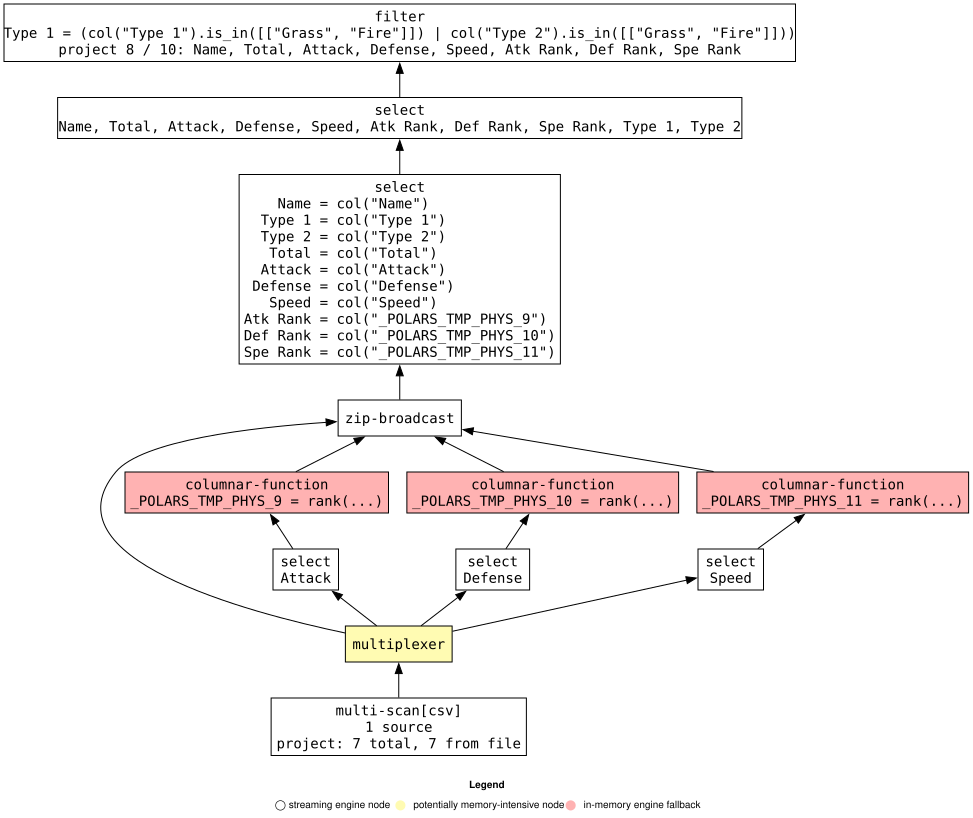

In [9]:
(
    lf
    .pipe(add_ranks)
    .pipe(keep_grass_or_fire)
    .pipe(keep_cols)
    .show_graph()
)

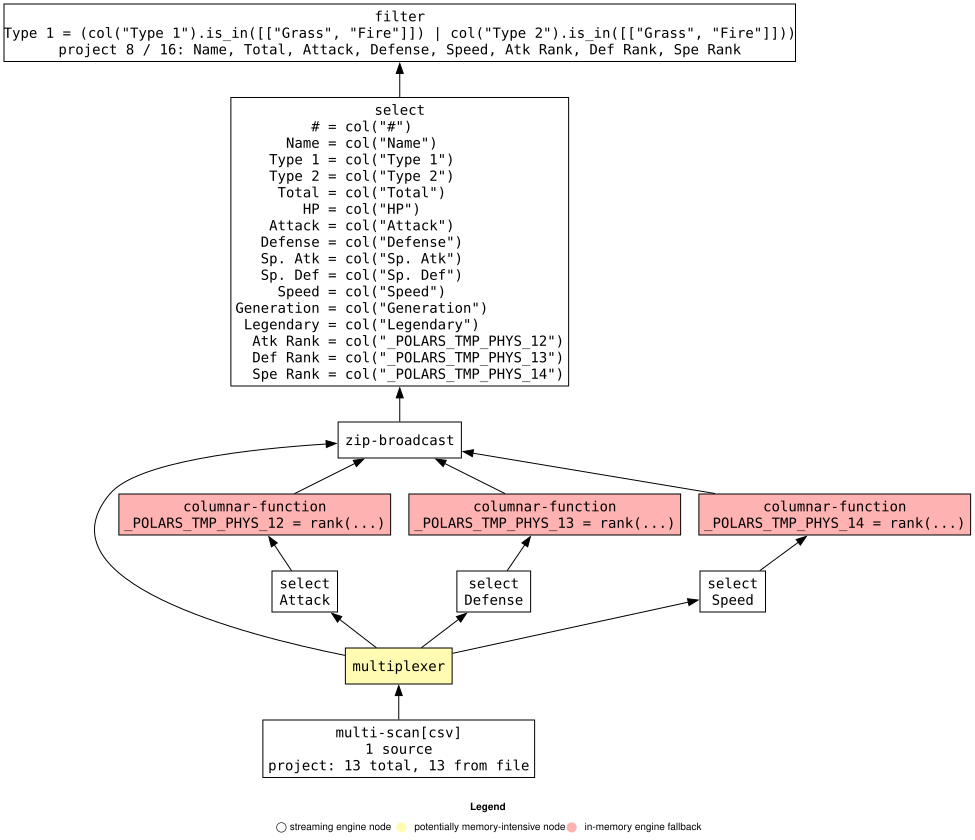

In [10]:
(
    lf
    .pipe(add_ranks)
    .pipe(keep_grass_or_fire)
    .pipe(keep_cols)
    .show_graph(optimized=False)
)

In [11]:
print(
    lf
    .pipe(add_ranks)
    .pipe(keep_grass_or_fire)
    .pipe(keep_cols)
    .explain()
)

simple π 8/8 ["Name", "Total", "Attack", ... 5 other columns]
  FILTER (col("Type 1").is_in([["Grass", "Fire"]]) | col("Type 2").is_in([["Grass", "Fire"]]))
  FROM
    simple π 10/10 ["Name", "Total", "Attack", ... 7 other columns]
       WITH_COLUMNS:
       [col("Attack").rank().alias("Atk Rank"), col("Defense").rank().alias("Def Rank"), col("Speed").rank().alias("Spe Rank")] 
        Csv SCAN [../data/pokemon.csv]
        PROJECT 7/13 COLUMNS
        ESTIMATED ROWS: 161


In [12]:
print(
    lf
    .pipe(add_ranks)
    .pipe(keep_grass_or_fire)
    .pipe(keep_cols)
    .explain(optimized=False)
)

SELECT [col("Name"), col("Total"), col("Attack"), col("Defense"), col("Speed"), col("Atk Rank"), col("Def Rank"), col("Spe Rank")]
  FILTER (col("Type 1").is_in([["Grass", "Fire"]]) | col("Type 2").is_in([["Grass", "Fire"]]))
  FROM
     WITH_COLUMNS:
     [col("Attack").rank().alias("Atk Rank"), col("Defense").rank().alias("Def Rank"), col("Speed").rank().alias("Spe Rank")] 
      Csv SCAN [../data/pokemon.csv]
      PROJECT */13 COLUMNS
      ESTIMATED ROWS: 161


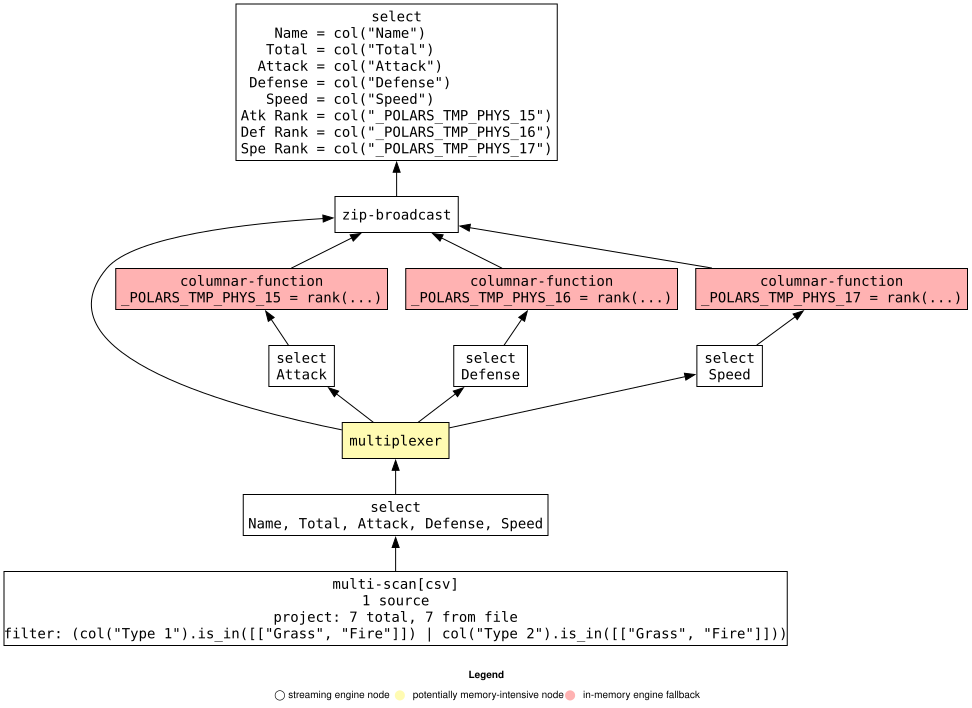

In [13]:
(
    lf
    .pipe(keep_grass_or_fire)
    .pipe(keep_cols)    
    .pipe(add_ranks)
    .show_graph()
)

### There is more...

In [15]:
print(
    lf
    .pipe(keep_grass_or_fire)
    .pipe(keep_cols)    
    .pipe(add_ranks)
    .explain(engine='streaming')
)

 WITH_COLUMNS:
 [col("Attack").rank().alias("Atk Rank"), col("Defense").rank().alias("Def Rank"), col("Speed").rank().alias("Spe Rank")] 
  simple π 5/5 ["Name", "Total", "Attack", ... 2 other columns]
    Csv SCAN [../data/pokemon.csv]
    PROJECT 7/13 COLUMNS
    SELECTION: (col("Type 1").is_in([["Grass", "Fire"]]) | col("Type 2").is_in([["Grass", "Fire"]]))
    ESTIMATED ROWS: 161


## Testing data quality with cuallee

### How to do it...

In [ ]:
from cuallee import Check, CheckLevel

In [ ]:
df = lf.collect()
df.head()

In [ ]:
check = Check(CheckLevel.WARNING, 'Completeness')
(
    check
    .is_complete('Name')
    .is_unique('Name')
    .validate(df)
)

In [ ]:
check = Check(CheckLevel.WARNING, 'Accepted Values')
accepted_types = (
    lf.select('Type 1')
    .unique()
    .collect()
    .to_series()
    .to_list()
)

(
    check
    .is_contained_in('Type 1', set(accepted_types))
    .validate(df)
    .select('check', 'column', 'rule', 'status')
)

In [ ]:
check = Check(CheckLevel.WARNING, 'Validation on Stats')
stats_cols = [
    'HP',
    'Attack',
    'Defense',
    'Sp. Atk',
    'Sp. Def',
    'Speed'
]
res_cols = [
    'check', 
    'column', 
    'rule', 
    'rows', 
    'violations', 
    'pass_rate', 
    'status'
]

(
    check
    .is_complete(stats_cols)
    .is_greater_than(stats_cols, 0)
    .validate(df)
    .select(res_cols)
)

In [ ]:
check = Check(CheckLevel.WARNING, 'Completeness')
cols = ['Name', 'Type 1', 'Type 2']
(
    check
    .are_complete(cols)
    .are_unique(cols)
    .validate(df)
    .select(
        'check', 
        'column', 
        'rule', 
        'rows', 
        'violations', 
        'pass_rate', 
        'status'
    )
)

### There is more...

In [ ]:
check = Check(CheckLevel.WARNING, 'Completeness')
result = (
    check
    .is_complete('Type 2')
    .validate(df)
    .select('status')[0,0]=='PASS'
)
assert result

## Getting started with Pytest

Please refer to `demo.py` and `test_demo.py`